# Практична робота 4.13 — Частина 1
## Transfer Learning: класифікація техніки з використанням репозиторію попередньо навчених моделей

**Тема 4. Заняття 13.** Практичне використання репозиторіїв аналітичних моделей в межах виконання індивідуальних (групових) проектів.

**Індивідуальне завдання:**
1. **Вибір моделі** з репозиторію попередньо навчених моделей.
2. **Адаптація** моделі (feature extraction → fine-tuning) до власного набору даних.
3. **Оцінка результатів** на валідаційних і тестових даних, оптимізація параметрів.
4. **Домашнє завдання:** інтеграція навченої моделі в симульовану інформаційну систему.

**Дані:** відкритий набір CIFAR-10 (дзеркало на Hugging Face `uoft-cs/cifar10`), лише класи техніки: **літак, автомобіль, корабель, вантажівка** — як навчальний відкритий замінник задачі «класифікація військової техніки» (реальні службові зображення в публічному репозиторії використовувати не можна).

**Модель з репозиторію:** `MobileNetV2` (ImageNet) з **Keras Applications** — легка (2.3 млн параметрів), швидко навчається на CPU, призначена для мобільних/польових пристроїв.

## 0. Імпорт бібліотек та налаштування

In [1]:
import os, io, time, urllib.request, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore", category=UserWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid", palette="muted")
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)
L = tf.keras.layers
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Завантаження та підготовка даних

Беремо по 1250 зображень на клас з train (1000 → навчання, 250 → валідація) і по 250 на клас з офіційного test CIFAR-10. Test використовується лише для фінальної оцінки.

In [2]:
CACHE = os.path.expanduser("~/.keras/datasets/cifar10_hf")
HF = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/{}-00000-of-00001.parquet"
CLASSES = {0: "літак", 1: "автомобіль", 8: "корабель", 9: "вантажівка"}
CLASS_NAMES = list(CLASSES.values())

def load_split(split, per_class):
    os.makedirs(CACHE, exist_ok=True)
    path = os.path.join(CACHE, f"{split}.parquet")
    if not os.path.exists(path):
        print("Завантаження", split, "...")
        urllib.request.urlretrieve(HF.format(split), path)
    d = pd.read_parquet(path)
    d = d[d.label.isin(CLASSES)].groupby("label").sample(n=per_class, random_state=RANDOM_STATE)
    X = np.stack([np.array(Image.open(io.BytesIO(r["bytes"]))) for r in d.img]).astype("uint8")
    y = d.label.map({k: i for i, k in enumerate(CLASSES)}).to_numpy().astype("int32")
    return X, y

X_all, y_all = load_split("train", 1250)
X_test, y_test = load_split("test", 250)
perm = np.random.default_rng(RANDOM_STATE).permutation(len(X_all))
X_all, y_all = X_all[perm], y_all[perm]
X_train, y_train = X_all[:4000], y_all[:4000]
X_val, y_val = X_all[4000:], y_all[4000:]
print("train", X_train.shape, "| val", X_val.shape, "| test", X_test.shape)
pd.DataFrame({"train": np.bincount(y_train), "val": np.bincount(y_val), "test": np.bincount(y_test)},
             index=CLASS_NAMES)

train (4000, 32, 32, 3) | val (1000, 32, 32, 3) | test (1000, 32, 32, 3)


,train,val,test
літак,1000,250,250
автомобіль,997,253,250
корабель,1002,248,250
вантажівка,1001,249,250


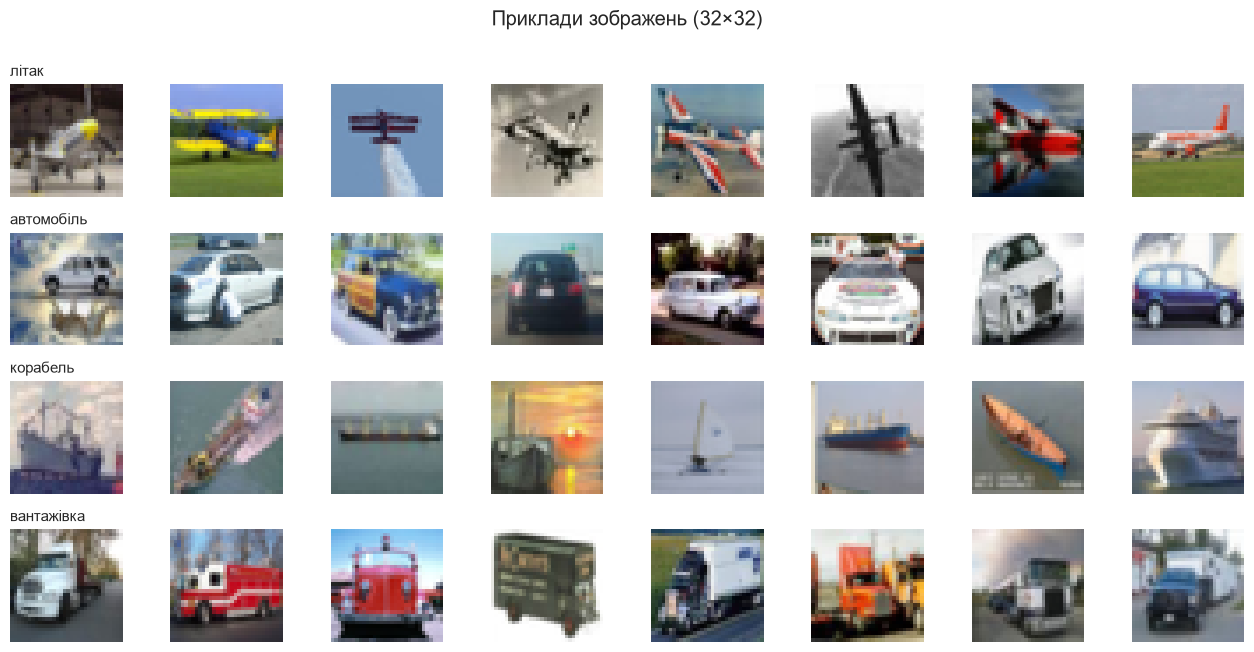

In [3]:
fig, axes = plt.subplots(4, 8, figsize=(13, 6.5))
for c in range(4):
    idx = np.where(y_train == c)[0][:8]
    for ax, i in zip(axes[c], idx):
        ax.imshow(X_train[i]); ax.axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=11)
plt.suptitle("Приклади зображень (32×32)", y=1.0); plt.tight_layout(); plt.show()

In [4]:
IMG = 96   # MobileNetV2 має ваги ImageNet для 96×96 — апскейлимо 32×32
BATCH = 64

def make_ds(X, y, size, shuffle=False):
    d = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        d = d.shuffle(len(X), seed=RANDOM_STATE)
    return (d.batch(BATCH)
             .map(lambda a, b: (tf.image.resize(tf.cast(a, tf.float32), (size, size)), b))
             .prefetch(tf.data.AUTOTUNE))

def augment():
    # новий екземпляр для кожної моделі (шари аугментації прив'язуються до розміру входу)
    return tf.keras.Sequential([L.RandomFlip("horizontal"), L.RandomTranslation(0.08, 0.08),
                                L.RandomZoom(0.1)], name="augmentation")

def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

early = lambda patience=3: tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=patience,
                                                             restore_best_weights=True)
results, histories = [], {}

## 2. Baseline: CNN з нуля (без попереднього навчання)

Щоб оцінити користь Transfer Learning, порівнюємо з невеликою CNN, яка навчається лише на наших 4000 зображеннях (нативний розмір 32×32).

In [5]:
def scratch_cnn():
    return tf.keras.Sequential([
        L.Input((32, 32, 3)), augment(), L.Rescaling(1 / 255.0),
        L.Conv2D(32, 3, padding="same", activation="relu"), L.BatchNormalization(), L.MaxPool2D(),
        L.Conv2D(64, 3, padding="same", activation="relu"), L.BatchNormalization(), L.MaxPool2D(),
        L.Conv2D(128, 3, padding="same", activation="relu"), L.BatchNormalization(), L.MaxPool2D(),
        L.GlobalAveragePooling2D(), L.Dropout(0.3), L.Dense(4, activation="softmax"),
    ], name="scratch_cnn")

tf.keras.utils.set_random_seed(RANDOM_STATE)
cnn = compile_model(scratch_cnn(), 1e-3)
t0 = time.time()
h = cnn.fit(make_ds(X_train, y_train, 32, True), validation_data=make_ds(X_val, y_val, 32),
            epochs=40, callbacks=[early(8)], verbose=0)   # з нуля навчається довше — більше терпіння
histories["A. CNN з нуля"] = h.history
results.append({"Підхід": "A. CNN з нуля", "Параметрів, що навчаються": cnn.count_params(),
                "Епох": len(h.history["loss"]), "Час, с": time.time() - t0,
                "Val accuracy": max(h.history["val_accuracy"])})
print(results[-1])

{'Підхід': 'A. CNN з нуля', 'Параметрів, що навчаються': 94660, 'Епох': 36, 'Час, с': 219.9309000968933, 'Val accuracy': 0.8420000076293945}


## 3. Transfer Learning, етап 1: feature extraction

Завантажуємо `MobileNetV2` з вагами ImageNet **без верхнього класифікатора** (`include_top=False`), **заморожуємо** всі шари і навчаємо лише нову «голову»: GlobalAveragePooling → Dropout → Dense(4).

In [6]:
tf.keras.utils.set_random_seed(RANDOM_STATE)
base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

inp = L.Input((IMG, IMG, 3))
x = augment()(inp)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)          # BatchNorm бази — в режимі inference
x = L.GlobalAveragePooling2D()(x)
x = L.Dropout(0.3)(x)
out = L.Dense(4, activation="softmax")(x)
tl_model = compile_model(tf.keras.Model(inp, out, name="mobilenetv2_tl"), 1e-3)

n_trainable = int(sum(np.prod(w.shape) for w in tl_model.trainable_weights))
print(f"Шарів у базі: {len(base.layers)} | всього параметрів: {tl_model.count_params():,} | навчаються: {n_trainable:,}")

t0 = time.time()
h1 = tl_model.fit(make_ds(X_train, y_train, IMG, True), validation_data=make_ds(X_val, y_val, IMG),
                  epochs=6, callbacks=[early()], verbose=0)
histories["B. Feature extraction"] = h1.history
results.append({"Підхід": "B. Feature extraction (база заморожена)", "Параметрів, що навчаються": n_trainable,
                "Епох": len(h1.history["loss"]), "Час, с": time.time() - t0,
                "Val accuracy": max(h1.history["val_accuracy"])})
print(results[-1])

Шарів у базі: 154 | всього параметрів: 2,263,108 | навчаються: 5,124


{'Підхід': 'B. Feature extraction (база заморожена)', 'Параметрів, що навчаються': 5124, 'Епох': 6, 'Час, с': 176.51075792312622, 'Val accuracy': 0.9200000166893005}


## 4. Transfer Learning, етап 2: fine-tuning

Розморожуємо **останні 30 шарів** бази (високорівневі ознаки) і донавчаємо з **малою швидкістю навчання** (1e-5), щоб не зруйнувати попередньо навчені ваги. Нижні шари (краї, текстури) лишаються замороженими — вони універсальні.

In [7]:
FINE_TUNE_AT = len(base.layers) - 30
base.trainable = True
for layer in base.layers[:FINE_TUNE_AT]:
    layer.trainable = False
compile_model(tl_model, 1e-5)
n_trainable_ft = int(sum(np.prod(w.shape) for w in tl_model.trainable_weights))
print(f"Розморожено шарів: {len(base.layers) - FINE_TUNE_AT} | параметрів, що навчаються: {n_trainable_ft:,}")

t0 = time.time()
h2 = tl_model.fit(make_ds(X_train, y_train, IMG, True), validation_data=make_ds(X_val, y_val, IMG),
                  epochs=6, callbacks=[early()], verbose=0)
histories["C. Fine-tuning"] = h2.history
results.append({"Підхід": "C. Fine-tuning (останні 30 шарів)", "Параметрів, що навчаються": n_trainable_ft,
                "Епох": len(h2.history["loss"]), "Час, с": time.time() - t0,
                "Val accuracy": max(h2.history["val_accuracy"])})
pd.DataFrame(results).round(3)

Розморожено шарів: 30 | параметрів, що навчаються: 1,531,524


,Підхід,"Параметрів, що навчаються",Епох,"Час, с",Val accuracy
0,A. CNN з нуля,94660,36,219.931,0.842
1,B. Feature extraction (база заморожена),5124,6,176.511,0.920
2,C. Fine-tuning (останні 30 шарів),1531524,4,160.808,0.922


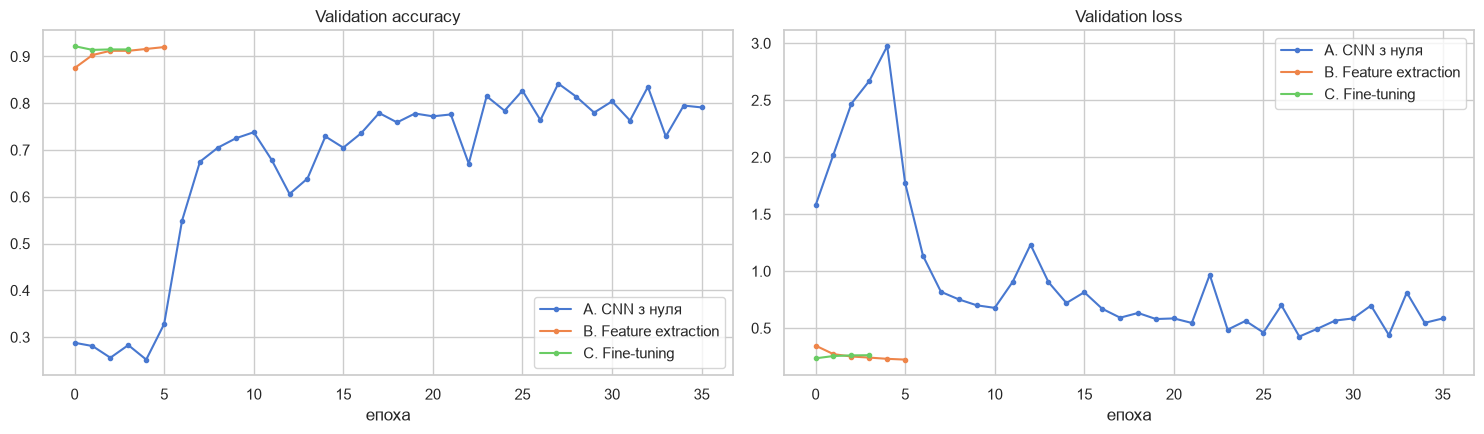

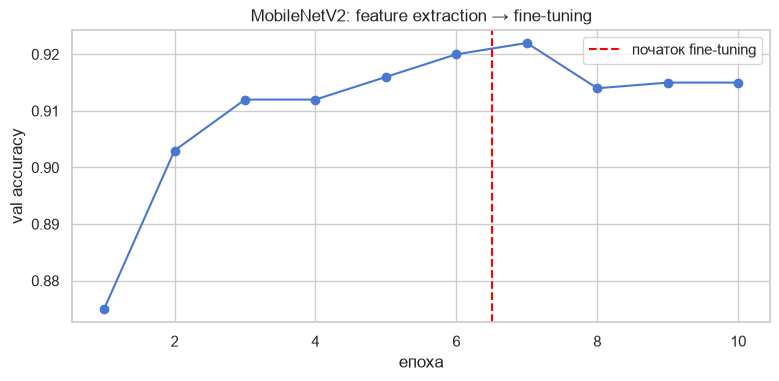

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, hist in histories.items():
    axes[0].plot(hist["val_accuracy"], marker="o", ms=3, label=name)
    axes[1].plot(hist["val_loss"], marker="o", ms=3, label=name)
axes[0].set_title("Validation accuracy"); axes[0].set_xlabel("епоха"); axes[0].legend()
axes[1].set_title("Validation loss"); axes[1].set_xlabel("епоха"); axes[1].legend()
plt.tight_layout(); plt.show()

ft_curve = histories["B. Feature extraction"]["val_accuracy"] + histories["C. Fine-tuning"]["val_accuracy"]
plt.figure(figsize=(9, 3.8))
plt.plot(range(1, len(ft_curve) + 1), ft_curve, "o-")
plt.axvline(len(histories["B. Feature extraction"]["val_accuracy"]) + 0.5, color="red", ls="--",
            label="початок fine-tuning")
plt.title("MobileNetV2: feature extraction → fine-tuning"); plt.xlabel("епоха"); plt.ylabel("val accuracy")
plt.legend(); plt.show()

## 5. Ефективність за малої кількості даних

Ключова перевага Transfer Learning — робота на **малих** наборах (типова ситуація для спеціалізованих задач, де розмічених зображень мало). Повторюємо порівняння, маючи лише **100 зображень на клас** (400 загалом).

In [9]:
small = np.concatenate([np.where(y_train == c)[0][:100] for c in range(4)])
Xs, ys = X_train[small], y_train[small]

tf.keras.utils.set_random_seed(RANDOM_STATE)
cnn_s = compile_model(scratch_cnn(), 1e-3)
cnn_s.fit(make_ds(Xs, ys, 32, True), validation_data=make_ds(X_val, y_val, 32), epochs=60,
          callbacks=[early(10)], verbose=0)

tf.keras.utils.set_random_seed(RANDOM_STATE)
base_s = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base_s.trainable = False
i_s = L.Input((IMG, IMG, 3))
o_s = L.Dense(4, activation="softmax")(L.Dropout(0.3)(L.GlobalAveragePooling2D()(
      base_s(tf.keras.applications.mobilenet_v2.preprocess_input(augment()(i_s)), training=False))))
tl_s = compile_model(tf.keras.Model(i_s, o_s), 1e-3)
tl_s.fit(make_ds(Xs, ys, IMG, True), validation_data=make_ds(X_val, y_val, IMG), epochs=15,
         callbacks=[early()], verbose=0)

small_cmp = pd.DataFrame({
    "400 зображень": [cnn_s.evaluate(make_ds(X_val, y_val, 32), verbose=0)[1],
                      tl_s.evaluate(make_ds(X_val, y_val, IMG), verbose=0)[1]],
    "4000 зображень": [results[0]["Val accuracy"], results[1]["Val accuracy"]],
}, index=["CNN з нуля", "MobileNetV2 (feature extraction)"])
small_cmp.round(3)

,400 зображень,4000 зображень
CNN з нуля,0.331,0.842
MobileNetV2 (feature extraction),0.870,0.920


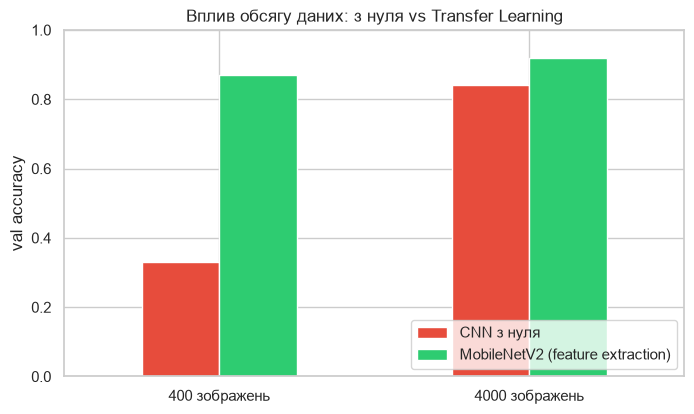

In [10]:
small_cmp.T.plot.bar(rot=0, figsize=(8, 4.5), color=["#e74c3c", "#2ecc71"])
plt.ylim(0, 1); plt.ylabel("val accuracy"); plt.title("Вплив обсягу даних: з нуля vs Transfer Learning")
plt.legend(loc="lower right"); plt.show()

## 6. Фінальна оцінка на test (одноразово)

Для фінального тесту беремо модель C (fine-tuning) — найкращу за validation accuracy — і для порівняння baseline A.

In [11]:
p_cnn = cnn.predict(make_ds(X_test, y_test, 32), verbose=0)
p_tl = tl_model.predict(make_ds(X_test, y_test, IMG), verbose=0)
final = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, p_cnn.argmax(1)), accuracy_score(y_test, p_tl.argmax(1))],
    "F1 (macro)": [f1_score(y_test, p_cnn.argmax(1), average="macro"), f1_score(y_test, p_tl.argmax(1), average="macro")],
}, index=["A. CNN з нуля", "C. MobileNetV2 fine-tuning"])
print(classification_report(y_test, p_tl.argmax(1), target_names=CLASS_NAMES, digits=3))
final.round(3)

              precision    recall  f1-score   support

       літак      0.982     0.852     0.912       250
  автомобіль      0.943     0.932     0.938       250
    корабель      0.887     0.944     0.915       250
  вантажівка      0.881     0.952     0.915       250

    accuracy                          0.920      1000
   macro avg      0.923     0.920     0.920      1000
weighted avg      0.923     0.920     0.920      1000



,Accuracy,F1 (macro)
A. CNN з нуля,0.842,0.841
C. MobileNetV2 fine-tuning,0.920,0.920


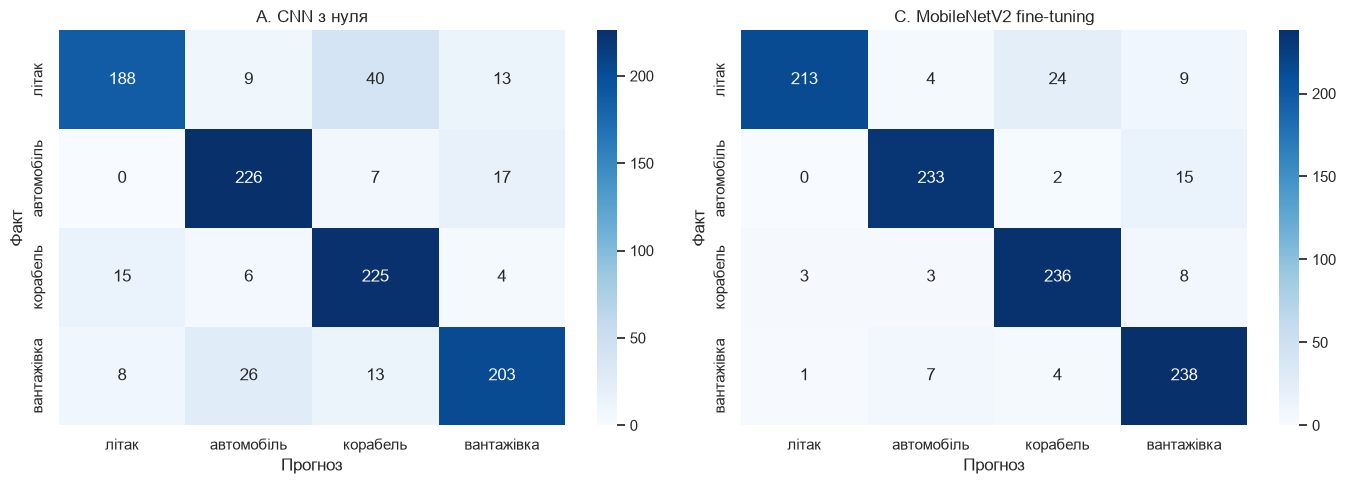

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, p) in zip(axes, [("A. CNN з нуля", p_cnn), ("C. MobileNetV2 fine-tuning", p_tl)]):
    sns.heatmap(confusion_matrix(y_test, p.argmax(1)), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(name); ax.set_xlabel("Прогноз"); ax.set_ylabel("Факт")
plt.tight_layout(); plt.show()

### 6.1 Аналіз помилок: найбільш «впевнені» помилки

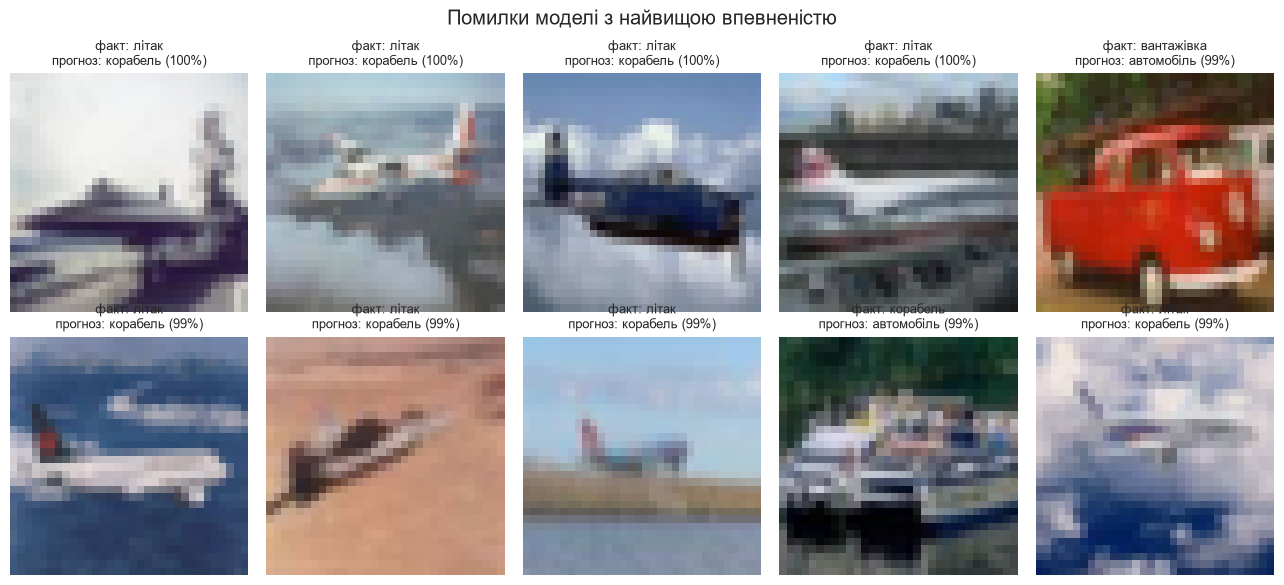

Прогноз,автомобіль,вантажівка,корабель,літак
Факт,,,,
автомобіль,0,15,2,0
вантажівка,7,0,4,1
корабель,3,8,0,3
літак,4,9,24,0


In [13]:
wrong = np.where(p_tl.argmax(1) != y_test)[0]
wrong = wrong[np.argsort(-p_tl[wrong].max(1))][:10]
fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(X_test[i]); ax.axis("off")
    ax.set_title(f"факт: {CLASS_NAMES[y_test[i]]}\nпрогноз: {CLASS_NAMES[p_tl[i].argmax()]} ({p_tl[i].max():.0%})", fontsize=9)
plt.suptitle("Помилки моделі з найвищою впевненістю"); plt.tight_layout(); plt.show()
pd.crosstab(pd.Series([CLASS_NAMES[v] for v in y_test[p_tl.argmax(1) != y_test]], name="Факт"),
            pd.Series([CLASS_NAMES[v] for v in p_tl.argmax(1)[p_tl.argmax(1) != y_test]], name="Прогноз"))

## 7. Домашнє завдання: інтеграція моделі в симульовану інформаційну систему

Моделюємо роботу модуля ІАС, який отримує потік знімків від засобів розвідки, класифікує об'єкти і формує звіт для аналітика. Ключова вимога — **людський контроль**: якщо впевненість моделі нижча за поріг, знімок не класифікується автоматично, а потрапляє в чергу на перевірку аналітиком.

Поріг впевненості обираємо на **validation** так, щоб точність автоматично класифікованих знімків була ≥ 97%.

Обраний поріг впевненості: 0.88


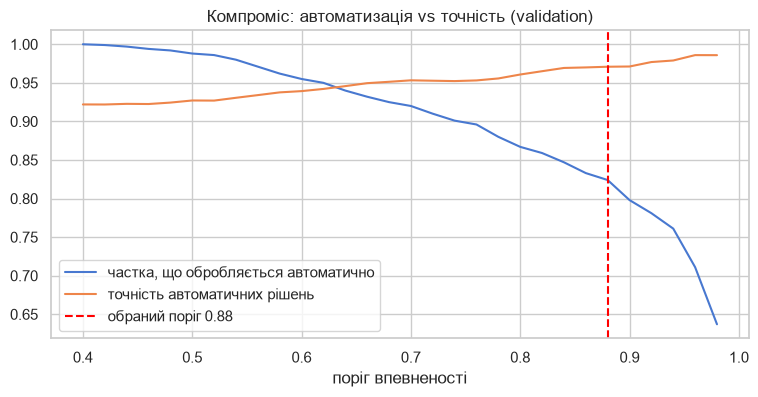

In [14]:
p_val = tl_model.predict(make_ds(X_val, y_val, IMG), verbose=0)
rows = []
for th in np.arange(0.40, 0.99, 0.02):
    auto = p_val.max(1) >= th
    rows.append({"поріг": th, "частка автоматично": auto.mean(),
                 "точність автоматичних": (p_val.argmax(1)[auto] == y_val[auto]).mean()})
th_table = pd.DataFrame(rows)
CONF_THRESHOLD = float(th_table.loc[th_table["точність автоматичних"] >= 0.97, "поріг"].min())
print(f"Обраний поріг впевненості: {CONF_THRESHOLD:.2f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(th_table["поріг"], th_table["частка автоматично"], label="частка, що обробляється автоматично")
ax.plot(th_table["поріг"], th_table["точність автоматичних"], label="точність автоматичних рішень")
ax.axvline(CONF_THRESHOLD, color="red", ls="--", label=f"обраний поріг {CONF_THRESHOLD:.2f}")
ax.set_xlabel("поріг впевненості"); ax.legend(); ax.set_title("Компроміс: автоматизація vs точність (validation)")
plt.show()

In [15]:
class ReconImageModule:
    """Модуль ІАС: класифікація знімків з маршрутизацією невпевнених випадків до аналітика."""

    def __init__(self, model, class_names, threshold, img_size=IMG):
        self.model, self.class_names, self.threshold, self.img_size = model, class_names, threshold, img_size

    def process(self, images, source_ids):
        x = tf.image.resize(tf.cast(images, tf.float32), (self.img_size, self.img_size))
        proba = self.model.predict(x, verbose=0)
        report = pd.DataFrame({
            "id": source_ids,
            "клас": [self.class_names[i] for i in proba.argmax(1)],
            "впевненість": proba.max(1).round(3),
        })
        report["статус"] = np.where(report["впевненість"] >= self.threshold,
                                    "автоматично", "НА ПЕРЕВІРКУ аналітику")
        return report

    @staticmethod
    def summary(report):
        auto = report[report["статус"] == "автоматично"]
        return {"всього знімків": len(report),
                "класифіковано автоматично": len(auto),
                "передано аналітику": len(report) - len(auto),
                "за класами (автоматично)": auto["клас"].value_counts().to_dict()}

module = ReconImageModule(tl_model, CLASS_NAMES, CONF_THRESHOLD)

# Симуляція: надходить пакет з 200 нових знімків (беремо з test, мітки модулю невідомі)
rng = np.random.default_rng(7)
batch_idx = rng.choice(len(X_test), 200, replace=False)
report = module.process(X_test[batch_idx], [f"IMG-{i:04d}" for i in batch_idx])
report.head(10)

,id,клас,впевненість,статус
0,IMG-0322,автомобіль,0.999,автоматично
1,IMG-0890,вантажівка,0.999,автоматично
2,IMG-0997,автомобіль,0.778,НА ПЕРЕВІРКУ аналітику
3,IMG-0401,автомобіль,1.000,автоматично
4,IMG-0404,автомобіль,0.999,автоматично
5,IMG-0862,вантажівка,0.988,автоматично
6,IMG-0661,корабель,0.999,автоматично
7,IMG-0407,автомобіль,1.000,автоматично
8,IMG-0906,вантажівка,0.944,автоматично
9,IMG-0746,корабель,0.994,автоматично


In [16]:
s = module.summary(report)
for k, v in s.items():
    print(f"{k}: {v}")

truth = y_test[batch_idx]
auto = (report["статус"] == "автоматично").to_numpy()
pred = np.array([CLASS_NAMES.index(c) for c in report["клас"]])
print(f"\nТочність автоматичних рішень (перевірка за прихованими мітками): {(pred[auto] == truth[auto]).mean():.1%}")
print(f"Точність, якби все класифікувалось автоматично:                {(pred == truth).mean():.1%}")
print(f"Частка помилок, які потрапили до аналітика: {((pred != truth) & ~auto).sum()} з {(pred != truth).sum()}")

всього знімків: 200
класифіковано автоматично: 163
передано аналітику: 37
за класами (автоматично): {'вантажівка': 51, 'корабель': 44, 'автомобіль': 38, 'літак': 30}

Точність автоматичних рішень (перевірка за прихованими мітками): 96.3%
Точність, якби все класифікувалось автоматично:                92.0%
Частка помилок, які потрапили до аналітика: 10 з 16


## 8. Висновки

| Підхід | Параметрів, що навчаються | Val accuracy | Test accuracy |
|---|---:|---:|---:|
| A. CNN з нуля (36 епох) | 94 660 | 0.842 | 0.842 |
| B. MobileNetV2, feature extraction (6 епох) | 5 124 | 0.920 | — |
| C. MobileNetV2, fine-tuning останніх 30 шарів (+4 епохи) | 1 531 524 | 0.922 | **0.920** |

1. **Вибір моделі.** MobileNetV2 з Keras Applications — компактна модель (2.3 млн параметрів) для обмежених обчислювальних ресурсів. Ваги ImageNet уже містять універсальні ознаки (краї, форми, текстури).
2. **Feature extraction.** Навчання лише «голови» (5 тис. параметрів, у 18 разів менше, ніж у CNN з нуля) за 6 епох дає 92.0% на validation проти 84.2% у CNN, яка навчалась з нуля 36 епох.
3. **Fine-tuning** у цьому експерименті дав лише незначний приріст (+0.2 п.п. на validation). Для 4 класів низької роздільності заморожених ознак ImageNet майже достатньо. Fine-tuning має більше сенсу, коли цільовий домен сильніше відрізняється від ImageNet (наприклад, супутникові чи тепловізійні знімки).
4. **Мало даних.** На 400 зображеннях (100 на клас) CNN з нуля майже не навчилась: 33.1% при 25% для випадкового вгадування. Transfer Learning дає 87.0%. Саме тут репозиторії попередньо навчених моделей найцінніші, бо для спеціалізованих задач розмічених даних зазвичай мало.
5. **Типові помилки** — візуально схожі класи. Найчастіша плутанина: *літак → корабель* (24 випадки, однорідний фон неба чи води) та *автомобіль ↔ вантажівка* (15 + 7). На зображеннях 32×32 частина таких прикладів неоднозначна і для людини.
6. **Інтеграція в ІАС:**
   - Поріг впевненості 0.88 підібрано на validation для точності автоматичних рішень ≥ 97%.
   - На новому пакеті з 200 знімків модуль автоматично класифікував 163 (81.5%) з точністю 96.3%. Це трохи нижче цілі, бо поріг, перенесений з validation на нові дані, не гарантує точно ту саму точність.
   - Решту 37 знімків передано аналітику; серед них 10 із 16 помилок моделі.
   - Модель працює як інструмент підтримки рішення, а не як заміна людини.

**Обмеження:** CIFAR-10 — цивільні зображення низької роздільності. Для реальної задачі потрібні:
- власні розмічені знімки;
- перевірка на domain shift (інший ракурс, погода, камуфляж);
- закритий контур обробки даних.